# UniverSeg — Final Results & Comparisons

This notebook collects the final recorded experiments for the UniverSeg project in one place.

### Experiments covered
1. Official pretrained model vs our 5,000-step model
2. Support-set size experiment
3. Support-set selection / sensitivity analysis
4. Representative qualitative-result checklist

**Final 'Our model' checkpoint:** `models/ours/checkpoints/universeg_5000_steps.pth`

**Core datasets:** OASIS, ACDC, DRIVE, CAMUS, PanDental, CHAOS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / 'results' / 'metrics'
print('Project root:', PROJECT_ROOT)
print('Results directory:', RESULTS_DIR)


Project root: d:\AI Paper\UniverSeg
Results directory: d:\AI Paper\UniverSeg\results\metrics


## 1. Final project configuration


In [2]:
config = {
    'Final checkpoint': 'models/ours/checkpoints/universeg_5000_steps.pth',
    'Training steps': 5000,
    'Training support size': 4,
    'Loss': 'Soft Dice',
    'Optimizer': 'Adam',
    'Learning rate': 1e-4,
    'Datasets': 'OASIS, ACDC, DRIVE, CAMUS, PanDental, CHAOS',
    'CHASE': 'Not included in clean final training',
}
display(pd.DataFrame(config.items(), columns=['Setting', 'Value']))

,Setting,Value
0,Final checkpoint,models/ours/checkpoints/universeg_5000_steps.pth
1,Training steps,5000
2,Training support size,4
3,Loss,Soft Dice
4,Optimizer,Adam
5,Learning rate,0.0001
6,Datasets,"OASIS, ACDC, DRIVE, CAMUS, PanDental, CHAOS"
7,CHASE,Not included in clean final training


## 2. Official pretrained vs our 5K model


In [3]:
# Recorded final comparison values
model_df = pd.DataFrame([
    ['OASIS', 414, 0.8635, 0.8109, 20],
    ['ACDC', 456, 0.6610, 0.8167, 20],
    ['DRIVE', 20, 0.3608, 0.2325, 16],
    ['CAMUS', 400, 0.7569, 0.7755, 396],
    ['PanDental', 116, 0.8426, 0.8514, 112],
    ['CHAOS', 2341, 0.6640, 0.5974, 2337],
], columns=['Dataset', 'Samples', 'Official_Pretrained', 'Our_5000_Steps', 'Queries'])

display(model_df)

# If final_results.csv exists, show it for verification.
csv_path = RESULTS_DIR / 'final_results.csv'
if csv_path.exists():
    print('\nExisting final_results.csv:')
    display(pd.read_csv(csv_path))
else:
    print('\nfinal_results.csv not found; using the recorded values above.')


,Dataset,Samples,Official_Pretrained,Our_5000_Steps,Queries
0,OASIS,414,0.8635,0.8109,20
1,ACDC,456,0.6610,0.8167,20
2,DRIVE,20,0.3608,0.2325,16
3,CAMUS,400,0.7569,0.7755,396
4,PanDental,116,0.8426,0.8514,112
5,CHAOS,2341,0.6640,0.5974,2337



Existing final_results.csv:


,Dataset,Samples,Official_Pretrained,Our_5000_Steps,Queries
0,OASIS,414,0.8635,0.8109,20
1,ACDC,456,0.6610,0.8167,20
2,DRIVE,20,0.3608,0.2325,16
3,CAMUS,400,0.7569,0.7755,396
4,PanDental,116,0.8426,0.8514,112
5,CHAOS,2341,0.6640,0.5974,2337


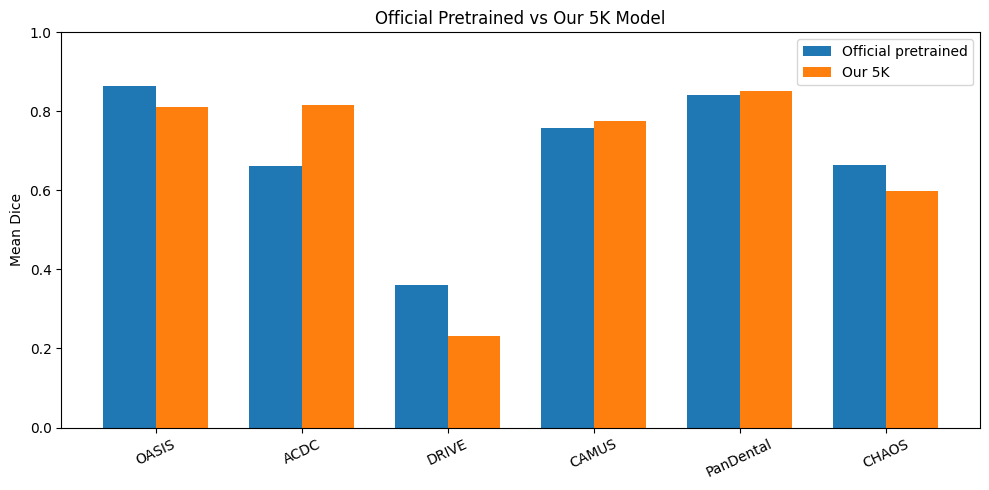

In [ ]:
x = np.arange(len(model_df))
width = 0.36
plt.figure(figsize=(10, 5))
plt.bar(x - width/2, model_df['Official_Pretrained'], width, label='Official pretrained')
plt.bar(x + width/2, model_df['Our_5000_Steps'], width, label='Our 5K')
plt.xticks(x, model_df['Dataset'], rotation=25)
plt.ylabel('Mean Dice')
plt.title('Official Pretrained vs Our 5K Model')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

The comparison is descriptive and domain-dependent. In the recorded evaluations, our model has higher mean Dice on ACDC, CAMUS and PanDental, while the official checkpoint has higher mean Dice on OASIS, DRIVE and CHAOS.

## 3. Support-set size experiment


In [5]:
support_df = pd.DataFrame([
    [1, 0.6627, 0.7681],
    [2, 0.8361, 0.7889],
    [4, 0.8635, 0.8037],
    [8, 0.8821, 0.8061],
    [16, 0.9045, 0.8083],
    [32, 0.9383, 0.8113],
    [64, 0.9310, 0.8143],
], columns=['Support_Size', 'Official_Pretrained', 'Our_5000_Steps'])
display(support_df)

csv_path = RESULTS_DIR / 'support_size_results.csv'
if csv_path.exists():
    print('\nExisting support_size_results.csv:')
    display(pd.read_csv(csv_path))
else:
    print('\nsupport_size_results.csv not found; using the recorded values above.')


,Support_Size,Official_Pretrained,Our_5000_Steps
0,1,0.6627,0.7681
1,2,0.8361,0.7889
2,4,0.8635,0.8037
3,8,0.8821,0.8061
4,16,0.9045,0.8083
5,32,0.9383,0.8113
6,64,0.9310,0.8143



Existing support_size_results.csv:


,Support_Size,Official_Pretrained,Our_5000_Steps
0,1,0.6627,0.7681
1,2,0.8361,0.7889
2,4,0.8635,0.8037
3,8,0.8821,0.8061
4,16,0.9045,0.8083
5,32,0.9383,0.8113
6,64,0.9310,0.8143


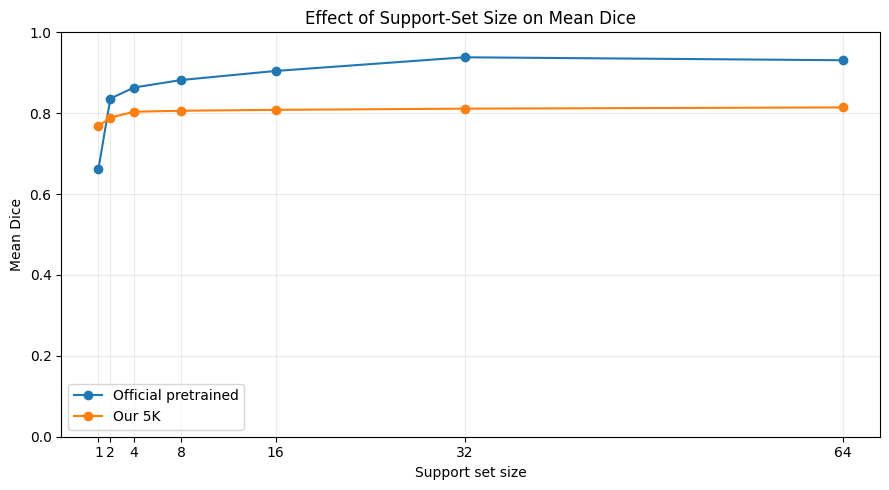

In [6]:
plt.figure(figsize=(9, 5))
plt.plot(support_df['Support_Size'], support_df['Official_Pretrained'], marker='o', label='Official pretrained')
plt.plot(support_df['Support_Size'], support_df['Our_5000_Steps'], marker='o', label='Our 5K')
plt.xlabel('Support set size')
plt.ylabel('Mean Dice')
plt.title('Effect of Support-Set Size on Mean Dice')
plt.xticks(support_df['Support_Size'])
plt.ylim(0, 1)
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation

The experiment tests whether increasing the number of labeled support examples changes performance. For the official checkpoint, Mean Dice rises substantially from support size 1 through 32, then decreases slightly at 64. For our 5K model, the change is more gradual across the tested support sizes.

## 4. Support-set selection / sensitivity analysis


In [7]:
selection_df = pd.DataFrame([
    ['Random support', 'Fixed seed 42; 4 supports', 0.8109],
    ['Previously selected support', '[12, 72, 267, 339]', 0.8020],
], columns=['Condition', 'Support', 'Mean_Dice'])
display(selection_df)

improvement = selection_df.loc[1, 'Mean_Dice'] - selection_df.loc[0, 'Mean_Dice']
print(f'Difference (selected - random): {improvement:+.4f}')

,Condition,Support,Mean_Dice
0,Random support,Fixed seed 42; 4 supports,0.8109
1,Previously selected support,"[12, 72, 267, 339]",0.8020


Difference (selected - random): -0.0089


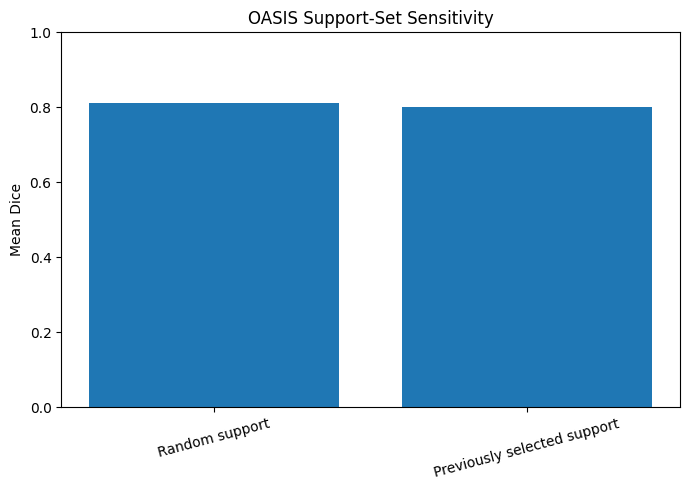

In [8]:
plt.figure(figsize=(7, 5))
plt.bar(selection_df['Condition'], selection_df['Mean_Dice'])
plt.ylabel('Mean Dice')
plt.title('OASIS Support-Set Sensitivity')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Interpretation

This is an exploratory sensitivity analysis, not evidence that one support-selection strategy is universally better. The recorded comparison shows that support composition can change the result: the previously selected support set scored 0.8020 versus 0.8109 for this particular random set on the same OASIS query set.

## 5. Important experiments that are not final

- **CHASE extension:** recorded mean Dice 0.0690; not included in final training.
- **BCE + Dice:** rejected after poor DRIVE behavior.
- **Weighted sampling:** separate experiment; not selected for the clean final setup.
- **10,000-step run:** loss stayed at 1.0000 and the run was stopped around step 3100; do not use as final.
- **KiTS19:** download stopped because the 3D CT imaging download was too heavy for the practical workflow.

## 6. Final report checklist

### Numerical results
- [x] Official vs our model table
- [x] Support-size table
- [x] Support sensitivity result

### Figures
- [x] Official vs our model plot
- [x] Support-size plot
- [x] Support sensitivity plot
- [ ] Representative qualitative predictions

### Report sections
1. Introduction
2. UniverSeg paper overview
3. Datasets and preprocessing
4. Model and training setup
5. Official vs our model results
6. Support-set size extension
7. Support-set sensitivity analysis
8. Qualitative results
9. Limitations
10. Conclusion

## 7. Recommended qualitative figures

For the final report, generate representative images in the format:

`Query | Ground Truth | Official Prediction | Our Prediction`

Use a small number of representative datasets/cases rather than filling the report with every prediction.